# BIL545 · Proje 1 · Vizeye kadarki konular (2.–7. haftalar)
**Veri Madenciliğinde İleri Konular · 2026–2027 Güz** · **Vize notu** · Teslim ve sunum: **8. hafta**

Bu defter projenin şablonudur. Grubunuz defteri kendi Drive'ına kopyalar (**Dosya → Drive'a kopya kaydet**), doldurur ve **iki yere** yükler: GitHub deposundaki `proje1/` klasörüne ve STIX'teki ödev alanına. Bütün yazılı cevaplar bu defterin metin hücrelerindedir; ayrı bir rapor yoktur.

**Kapsam grup tipine göre:** 1–3 kişilik gruplar Bölüm 1–3'ü, 4 kişilik gruplar ek olarak Ek paket 1'i, 5 kişilik gruplar Ek paket 1 ve 2'yi yapar. Grubunuzun yapmadığı ek paket bölümlerini silin. Defterin sonundaki **katkı beyanı puanlanır**; sunumda her üye en az bir alt başlığı anlatır.

**Teslimden önce:** Çalışma zamanını sıfırlayıp **Çalışma Zamanı → Tümünü çalıştır** ile defteri baştan sona hatasız çalıştırın.

**Puanlama:** Başarım puanlanmaz. Her bölüm kurulumun doğruluğu (%30), kararların gerekçesi (%25), dürüst raporlama (%25), yorum (%15) ve teknik düzene (%5) göre puanlanır. Ayrıntılar: *Proje 1 ve Proje 2 Yönergesi*.

## Grup bilgisi

 Emircan Demir,
 Mehmet Tankut Yolsal,
 Şahin Güngördü,
 Belgin Yavuz

**Grup adı:**  
**GitHub deposu:**  
**Seçilen konu:** 9.5 Online alışverişte satın alma niyeti  
**Grup tipi:**  4 kişi: + Ek paket 1

**Veri kümesi ve sorumuz (tek cümle):** Online Shoppers Intention
Oturum satınalmayla bitti mi?

In [30]:
#from google.colab import drive
#drive.mount('/content/drive')
#%cd "/content/drive/MyDrive/"
#!git config --global user.name "belginbyavuz"
#!git config --global user.email "belginbyavuz@gmail.com"
#!git commit -m "Proje dosyaları güncellendi"
#%cd "/content/drive/MyDrive/Colab Notebooks/"
#%ls
!git init
#!git add BIL545_Proje1_V1.ipynb

hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/drive/MyDrive/Colab Notebooks/.git/


## Hazırlık

In [ ]:
import sys, numpy as np, pandas as pd, sklearn
SEED = 42
np.random.seed(SEED)
print("Python      ", sys.version.split()[0]); print("numpy       ", np.__version__)
print("pandas      ", pd.__version__);          print("scikit-learn", sklearn.__version__)



Python       3.13.16
numpy        2.1.3
pandas       2.2.3
scikit-learn 1.6.1


### Veriyi yükleme
**Kaynak:**  **Lisans:**  **İndirme / yükleme adımı:**

In [ ]:
#df = None  # pd.read_csv(...) ya da fetch_openml(...)
df = pd.read_csv("/online_shoppers_intention.csv")
df.head()
df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


# Bölüm 1 · Veri, ön işleme ve sızıntı *(ağırlık 30)*
**Makale:** Kaufman vd. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD*, 6(4).

**Okuma notu (3–4 cümle):** …

### 1.1 Veri künyesi
| Soru | Cevap |
|---|---|
| Kim, hangi amaçla topladı? |Kullanıcıların satın alma niyetlerini tahmin etmek amacıyla, farklı kullanıcılara ait 12.330 oturumdan oluşan ve bir yıllık bir dönemi kapsayan şekilde toplanmıştır. |
| Hangi dönemi kapsıyor? | 1 yıllık bir dönemi kapsıyor. Hangi yıla ait olduğu belirtilmemiş.|
| Hedef gerçek olgu mu, vekil mi? |Hedef değişken revenuedur  ve hedef doğrudan gözlemlenebilen gerçek olgudur.  |
| Kimler eksik temsil ediliyor olabilir? |İnternet erişimi olmayan veya online alışverişi kullanmayan özellikle yaşlılar eksik temsil ediliyor olabilir |
| Lisans |Creative Commons Attribution 4.0 International (CC BY 4.0) |


**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*


In [ ]:
# Gerekirse destekleyici kod
df.head()


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…Hedef değişkenin revenue olduğu tespit edildi.

### 1.2 Keşifsel analiz
Boyut; saklama ve ölçek tipleri; hedef dağılımı; yinelenen satırlar; künye tablosu (tip, eksik oranı, farklı değer sayısı, sıfır oranı); şüpheli öznitelik listesi.

In [ ]:
#Boyut; saklama tipleri
#print(df.dtypes)

#Hedef dağılımı
#df['Revenue'].value_counts()

#yinelenen satırları gösterir
#df[df.duplicated()]
#toplam yinelenen satır sayısını gösterir
#df.duplicated().sum()

#KUNYE TABLOSU
summary_data = []
for col in df.columns:
    tip = df[col].dtype
    eksik_orani = df[col].isnull().mean()
    #Eksik oranın sıfır çıkması o columnda hiç null değer olmadığını gösterir. Veri temiz ve kaliteli
    farkli_deger = df[col].nunique()
    #farklı değer  o sütunda yeralan benzersiz değerlerin sayısını verir.
    # Sıfır oranı sadece sayısal sütunlar için hesaplanır. Değeri sıfır olanların ortalaması alınır.
    if pd.api.types.is_numeric_dtype(df[col]):
        sifir_orani = (df[col] == 0).mean()
    else:
        sifir_orani = "-"
    summary_data.append(
        [col, tip, eksik_orani, farkli_deger, sifir_orani]
    )
summary_df = pd.DataFrame(
    summary_data,
    columns=[
        "Öznitelik",
        "Tip",
        "Eksik Oranı",
        "Farklı Değer Sayısı",
        "Sıfır Oranı",
    ],
)
summary_df.set_index("Öznitelik", inplace=True)
print(summary_df)


                             Tip  Eksik Oranı  Farklı Değer Sayısı Sıfır Oranı
Öznitelik                                                                     
Administrative             int64          0.0                   27    0.467802
Administrative_Duration  float64          0.0                 3335    0.478751
Informational              int64          0.0                   17    0.786618
Informational_Duration   float64          0.0                 1258    0.804947
ProductRelated             int64          0.0                  311    0.003082
ProductRelated_Duration  float64          0.0                 9551    0.061233
BounceRates              float64          0.0                 1872    0.447526
ExitRates                float64          0.0                 4777    0.006164
PageValues               float64          0.0                 2704    0.778589
SpecialDay               float64          0.0                    6     0.89854
Month                     object          0.0       

#Boyut; saklama tiplerini df.types ile yazdırabiliriz. Toplam 18 özniteliğin 7 tanesi int64(tamsayı) iken 7 tanesi float64(ondalıklı), 2 tanesi object(karma veri) ve 2 tanesi de booldur(True/false).

Ölçek Tiplerine ise manuel bakıyoruz.
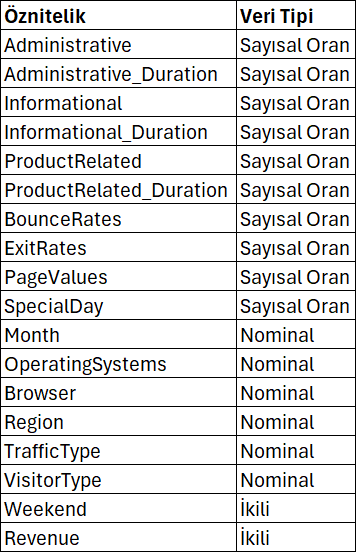


Hedef dağılımda ise kullanıcıların 10422sinin satınalma niyetinin olmadığını ve 1908'inin ise satınalma davranışı sergilediğini görüyoruz.
Yinelen satırlarda 125 tane duplicated satır olduğunu görüyoruz.


#Şüpheli Öznitelik Listesi

Şüpheli öznitelikleri belirlemek için hazırladığımız künye tablosunun sonuçlarına bakmamız gerekiyor.
1.Eksik oranı yükseK (Yok)
2.çok az benzersiz değere sahip (Specialday, Month, Operating System)
3.sıfır oranı şüpheli düzeyde olanları listeye ekleyeceğiz. (OperatingSystems,Browser, Region, Traffic Type, Visitor Type)



### 1.3 Eksiklik analizi
Eksik kodlarını `NaN`'a çevirin; deseni görselleştirin; en çok eksiği olan iki sütun için MCAR / MAR / MNAR tahmini; `add_indicator` etkisi.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*
Eksik Oran tüm öznitelikler için sıfırdır. Datasetimizde eksiklik olmadığı için veri setimizde doldurulması gereken eksik değer bulunmuyor.

…

### 1.4 Kategorik kodlama
Yüksek kardinaliteli bir sütunda bire-bir, nadir kategorileri birleştiren bire-bir ve kat dışı hedef kodlama; hedef kodlamanın bir kez yanlış uygulanması.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 1.5 Sızıntı deneyi
Ön işlemenin bütün veride yapıldığı kurulum (yanlış) ile `Pipeline` içinde yapıldığı kurulum (doğru); hata çubuklarıyla.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 1.6 Baseline ve ilk model
`DummyClassifier` ve tek bir basit model, sızıntısız hat içinde.

In [ ]:
from sklearn.dummy import DummyClassifier

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 1.7 Weka ile bağımsız kontrol
ZeroR ve J48, 10 kat çapraz doğrulama; çıktıyı yapıştırın ve Python ile tutarlılığını yorumlayın.

In [ ]:
weka_cikti = """

"""

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Bölüm 2 · Sınıflandırma ve dürüst model değerlendirme *(ağırlık 30)*
**Makale:** Dietterich (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7).

**Okuma notu (3–4 cümle):** …

### 2.1 Model karşılaştırması
Baseline, karar ağacı, k-NN, rastgele orman, gradyan artırma; tekrarlı katmanlı ÇD; ortalama ± std tablosu ve kutu grafiği; ölçüt seçiminin gerekçesi.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.2 Karar ağacının yorumu
`export_text` ile kök ve ilk iki düzeyin alan bilgisiyle yorumu.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.3 Optimist yanlılık
`GridSearchCV.best_score_` ile iç içe ÇD skorunun karşılaştırması.

In [ ]:
from sklearn.model_selection import GridSearchCV

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.4 İstatistiksel test
En iyi iki modelin farkı: McNemar ya da 5×2 ÇD t-testi. "Fark anlamlı çıkmadı" tam puanlık bir sonuçtur.

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.5 Proje 2'ye aktarılacak model ve çıktılar
En iyi modeli ve protokolü gerekçesiyle seçin; temizlenmiş veriyi ve hattı kaydedin.

In [ ]:
# import joblib
# df_temiz.to_csv("p1_temiz_veri.csv", index=False)
# joblib.dump(hat, "p1_hat.joblib")

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Bölüm 3 · Veri küpü ve birliktelik analizi *(ağırlık 15)*
**Makale:** Wu, Chen ve Han (2010). Re-examination of interestingness measures in pattern mining. *Data Mining and Knowledge Discovery*, 21(3).

**Okuma notu (3–4 cümle):** …

### 3.1 Kısa veri küpü
Bir olgu ve en az üç boyut; roll-up ve drill-down; toplamdaki bir eğilimin alt gruplarda değişip değişmediği (Simpson paradoksu).

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.2 Birliktelik: seçenek ve kurulum
İşlem bilgisi varsa **A**, yoksa **B**. Veri değiştirilmez.

**Seçenek:** …

In [ ]:
!pip -q install mlxtend
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.3 Kurallar ve ilgi ölçütleri
**A:** işlem tanımı; Apriori ve FP-Growth, en az üç `min_support`; güven, lift ve Kulczynski; null-invariance testi.
**B:** ayrıklaştırma ve "öznitelik = değer" işlemleri; hedefe yönelik kurallar; lift ve Kulczynski; Proje 1 modelinin önemli öznitelikleriyle karşılaştırma.
İki seçenekte de üç kuralın alan bilgisiyle yorumu.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.4 Weka ile kontrol
Aynı eşiklerde Weka Apriori çıktısı.

In [ ]:
weka_apriori = """

"""

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Ek paket 1 · Topluluk yöntemleri ve öznitelik önemi *(4 ve 5 kişilik gruplar)*

### E1.1 Budama eğrisi
Karar ağacında `ccp_alpha` taraması; ağaç boyutu ile eğitim ve test başarımı aynı grafikte.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E1.2 Doyum eğrisi
Rastgele ormanda ağaç sayısı 1–500; OOB ve test hatası.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E1.3 Öznitelik önemi
Rastgele bir sütun ekleyin; Gini önemi ve permütasyon önemi sıralamalarını karşılaştırın.

In [ ]:
from sklearn.inspection import permutation_importance

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Ek paket 2 · Öznitelik seçimi ve kararlılığı *(5 kişilik gruplar)*
**Makale:** Meinshausen ve Bühlmann (2010). Stability selection. *JRSS B*, 72(4).

**Okuma notu (3–4 cümle):** …

### E2.1 Üç aile
Filtre, sarmalayıcı ve gömülü birer yöntem, hattın içinde.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E2.2 Kararlılık
100 farklı %70'lik alt örneklemde seçimi tekrarlayın; seçilme oranlarını çizin.

In [ ]:
from collections import Counter

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E2.3 Seçimin katkısı
Seçimli ve seçimsiz hattın dürüst karşılaştırması.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

## Varsayım defteri
Bu projede verdiğiniz her kararı ve gerekçesini madde madde yazın (ön işleme, ölçüt, eşik, parametre, veri seçimi). En az bir kararın bölümlerin makalelerinden birine dayandığını belirtin.

- **Karar:** … — **Gerekçe:** …
- **Karar:** … — **Gerekçe:** …

## Katkı beyanı (zorunlu)
Her üyenin hangi alt başlıklarda (ör. 1.3, 2.4) ve hangi işlerde (kod, analiz, yorum, sunum hazırlığı) çalıştığını somut olarak yazın. Katkı puanı bu beyana göre verilir: somutluk %30, pay %30, GitHub commit geçmişiyle tutarlılık %25, sunumla tutarlılık %15.

| Üye | Çalıştığı alt başlıklar ve işler | Sunumda anlattığı alt başlık |
|---|---|---|
| Üye 1 | | |
| Üye 2 *(varsa)* | | |
| Üye 3 *(varsa)* | | |
| Üye 4 *(varsa)* | | |
| Üye 5 *(varsa)* | | |

## Yapay zekâ beyanı
Yapay zekâ araçları kullandıysanız hangi aşamada ve ne için kullandığınızı yazın. Kullanmadıysanız "Kullanılmadı" yazın.

…

## Kaynaklar
- …